# Heat Kernelとグラフ上の拡散

## 概要

グラフの辺に沿って熱が移る過程を、ラプラシアンと行列指数関数で表す。3頂点の例で解を導出し、Pythonで熱の分布、Heat Kernel、固有値による減衰を確認する。最後に、2つの頂点群を結ぶ辺の重みと拡散の速さを比較する。

## 実行環境

カーネルは `wa-src(3.14.6)`、Pythonは3.14.6である。使用ライブラリの版は下に出力する。Notebookのあるディレクトリで上から実行すると、図を `106_nb_files` にSVG形式で保存する。数値の表示は有効数字3桁とし、計算には丸める前の値を用いる。

In [1]:
import platform
import sys
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import scipy
from IPython.display import display
from matplotlib.ticker import FuncFormatter
from scipy.linalg import eigh, expm
from scipy.sparse.linalg import expm_multiply

%matplotlib inline
# 未信頼のNotebookでも表示できるよう、出力にはPNGも埋め込む。
%config InlineBackend.figure_formats = {'svg', 'png'}

assert sys.version_info[:3] == (3, 14, 6)
print('環境名: wa-src(3.14.6)')
print(f'Python: {platform.python_version()} / OS: {platform.system()}')
for module in (np, scipy, matplotlib, nx):
    print(f'{module.__name__}: {module.__version__}')

OUT = Path('106_nb_files')
OUT.mkdir(exist_ok=True)


def sig3(value):
    """末尾のゼロも残し、有効数字3桁で表示する。"""
    return format(float(value), '#.3g')


np.set_printoptions(formatter={'float_kind': sig3}, linewidth=90)
plt.rcParams.update({'font.size': 11, 'svg.hashsalt': 'heat106'})


def show_math(formula):
    # LaTeX出力は \(...\)、HTML出力は $$...$$ で囲む。
    display({
        'text/latex': r'\(' + formula + r'\)',
        'text/html': '<div>$$' + formula + '$$</div>',
    }, raw=True)


def format_axes(ax):
    # 連続量の軸にも、本文と同じ表示精度を適用する。
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: sig3(x)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: sig3(x)))
    ax.grid(alpha=0.250)


def save_svg(fig, name):
    """保存したSVGと同じ内容をNotebookの出力にも埋め込む。"""
    path = OUT / name
    fig.savefig(path, format='svg', bbox_inches='tight', metadata={'Date': None})
    display(fig)
    plt.close(fig)

環境名: wa-src(3.14.6)
Python: 3.14.6 / OS: Darwin
numpy: 2.5.4
scipy: 1.18.1
matplotlib: 3.11.2
networkx: 3.7


## 1. 辺を通る熱の移動

2頂点以上の有限の連結な無向グラフを考える。自己ループはなく、辺の重みは $w_{ij}=w_{ji}\geq0$ とする。各頂点の熱容量は1、拡散係数は辺の重みに含める。隣接行列を $\mathbf{W}=(w_{ij})$、重み付き次数を $d_i=\sum_jw_{ij}$ とすると、組合せラプラシアンは次式である。

$$
\mathbf{D}=\operatorname{diag}(d_1,\ldots,d_n),\qquad
\mathbf{L}=\mathbf{D}-\mathbf{W}.
$$

頂点 $i$ の熱量を $u_i(t)$ とする。隣接頂点との熱量の差に比例して流入するため、

$$
\frac{du_i}{dt}
=\sum_jw_{ij}(u_j-u_i)
=\sum_jw_{ij}u_j-d_i u_i
=-(\mathbf{L}\mathbf{u})_i.
$$

これを列ベクトルでまとめる。初期値は $\mathbf{u}_0$ とする。

$$\frac{d\mathbf{u}}{dt}=-\mathbf{L}\mathbf{u},\qquad\mathbf{u}(0)=\mathbf{u}_0$$

ラプラシアン:
array([[1.00, -1.00, 0.00],
       [-1.00, 2.00, -1.00],
       [0.00, -1.00, 1.00]])


$$\mathbf{L}=\begin{pmatrix}1&-1&0\\-1&2&-1\\0&-1&1\end{pmatrix},\qquad\mathbf{u}_0=\begin{pmatrix}1\\0\\0\end{pmatrix}$$

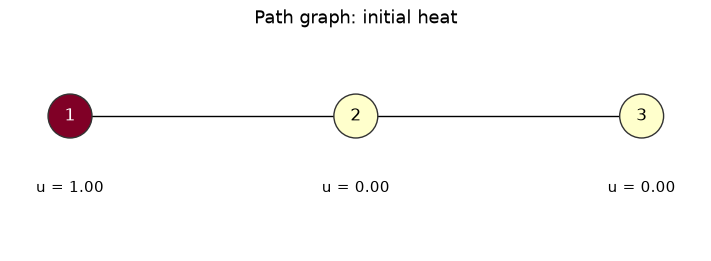

In [2]:
show_math(r'\frac{d\mathbf{u}}{dt}=-\mathbf{L}\mathbf{u},'
          r'\qquad\mathbf{u}(0)=\mathbf{u}_0')

# 頂点番号の順序を固定し、行列の添字と一致させる。
G = nx.path_graph([1, 2, 3])
L = nx.laplacian_matrix(G, nodelist=[1, 2, 3]).toarray().astype(float)
u0 = np.array([1, 0, 0], dtype=float)
print('ラプラシアン:')
pprint(L)
show_math(r'\mathbf{L}=\begin{pmatrix}1&-1&0\\-1&2&-1\\0&-1&1\end{pmatrix},'
          r'\qquad\mathbf{u}_0=\begin{pmatrix}1\\0\\0\end{pmatrix}')

fig, ax = plt.subplots(figsize=(7, 2.50), layout='constrained')
positions = {1: (0, 0), 2: (1, 0), 3: (2, 0)}
nx.draw_networkx(G, positions, ax=ax, node_color=u0, cmap='YlOrRd',
                 vmin=0, vmax=1, node_size=1000, edgecolors='#333333',
                 font_color={1: 'white', 2: 'black', 3: 'black'})
for node, value in zip(G.nodes, u0):
    ax.text(positions[node][0], -0.0900, f'u = {sig3(value)}', ha='center')
ax.set_ylim(-0.160, 0.100)
ax.set_title('Path graph: initial heat')
ax.axis('off')
save_svg(fig, '01_path_graph.svg')

## 2. Heat Kernelを導く

行列指数関数を級数で定義し、項別に微分する。有限次元では、この級数と導関数の級数は有界な時間区間で一様収束する。

$$
\begin{aligned}
\mathbf{H}_t&=e^{-t\mathbf{L}}
=\sum_{m=0}^{\infty}\frac{(-t)^m}{m!}\mathbf{L}^m,\\
\frac{d\mathbf{H}_t}{dt}
&=\sum_{m=1}^{\infty}\frac{m(-1)^m t^{m-1}}{m!}\mathbf{L}^m\\
&=-\mathbf{L}\sum_{r=0}^{\infty}\frac{(-t)^r}{r!}\mathbf{L}^r
=-\mathbf{L}\mathbf{H}_t.
\end{aligned}
$$

$t=0$ では $m=0$ の項だけが残り、$\mathbf{H}_0=\mathbf{I}$ となる。したがって次式が初期値問題を満たす。$\mathbf{H}_t$ をHeat Kernelと呼ぶ。その $(i,j)$ 成分は、頂点 $j$ に単位量の熱を置いたときの頂点 $i$ の熱量である。

In [3]:
show_math(r'\boxed{\mathbf{u}(t)=\mathbf{H}_t\mathbf{u}_0'
          r'=e^{-t\mathbf{L}}\mathbf{u}_0}')

# np.expは要素ごとの指数関数なので、行列指数関数にはexpmを用いる。
H1 = expm(-L)
print('H(1):')
pprint(H1)
print('u(1):')
pprint(H1 @ u0)

$$\boxed{\mathbf{u}(t)=\mathbf{H}_t\mathbf{u}_0=e^{-t\mathbf{L}}\mathbf{u}_0}$$

H(1):
array([[0.526, 0.317, 0.158],
       [0.317, 0.367, 0.317],
       [0.158, 0.317, 0.526]])
u(1):
array([0.526, 0.317, 0.158])


## 3. 3頂点の場合を手計算する

固有値は特性方程式から求まる。第1行で行列式を展開すると、

$$
\begin{aligned}
\det(\lambda\mathbf{I}-\mathbf{L})
&=(\lambda-1)\{(\lambda-2)(\lambda-1)-1\}-(\lambda-1)\\
&=(\lambda-1)(\lambda^2-3\lambda)
=\lambda(\lambda-1)(\lambda-3).
\end{aligned}
$$

よって固有値は $0,1,3$ である。$\mathbf{L}\mathbf{q}=\lambda\mathbf{q}$ に代入すると、$\lambda=0$ では3成分が等しく、$\lambda=1$ では第2成分が0、第3成分が第1成分の負になる。$\lambda=3$ では第2成分が第1成分の $-2$ 倍、第3成分が第1成分と等しくなる。長さを1にそろえると次式を得る。

In [4]:
show_math(r'\mathbf{q}_0=\frac{1}{\sqrt{3}}\begin{pmatrix}1\\1\\1\end{pmatrix},'
          r'\quad\mathbf{q}_1=\frac{1}{\sqrt{2}}\begin{pmatrix}1\\0\\-1\end{pmatrix},'
          r'\quad\mathbf{q}_2=\frac{1}{\sqrt{6}}\begin{pmatrix}1\\-2\\1\end{pmatrix}')
show_math(r'\mathbf{q}_0^{\mathsf T}\mathbf{u}_0=\frac{1}{\sqrt{3}},'
          r'\quad\mathbf{q}_1^{\mathsf T}\mathbf{u}_0=\frac{1}{\sqrt{2}},'
          r'\quad\mathbf{q}_2^{\mathsf T}\mathbf{u}_0=\frac{1}{\sqrt{6}}')

$$\mathbf{q}_0=\frac{1}{\sqrt{3}}\begin{pmatrix}1\\1\\1\end{pmatrix},\quad\mathbf{q}_1=\frac{1}{\sqrt{2}}\begin{pmatrix}1\\0\\-1\end{pmatrix},\quad\mathbf{q}_2=\frac{1}{\sqrt{6}}\begin{pmatrix}1\\-2\\1\end{pmatrix}$$

$$\mathbf{q}_0^{\mathsf T}\mathbf{u}_0=\frac{1}{\sqrt{3}},\quad\mathbf{q}_1^{\mathsf T}\mathbf{u}_0=\frac{1}{\sqrt{2}},\quad\mathbf{q}_2^{\mathsf T}\mathbf{u}_0=\frac{1}{\sqrt{6}}$$

直交する固有ベクトルに初期値を分解すると、各係数は $dc_k/dt=-\lambda_kc_k$ に従う。$d(e^{\lambda_kt}c_k)/dt=0$ なので、$c_k(t)=e^{-\lambda_kt}c_k(0)$ である。係数を戻し、成分ごとに足し合わせる。

$$\begin{aligned}\mathbf{u}(t)&=\sum_{k=0}^{2}e^{-\lambda_k t}\mathbf{q}_k(\mathbf{q}_k^{\mathsf T}\mathbf{u}_0)\\&=\frac{1}{3}\begin{pmatrix}1\\1\\1\end{pmatrix}+\frac{e^{-t}}{2}\begin{pmatrix}1\\0\\-1\end{pmatrix}+\frac{e^{-3t}}{6}\begin{pmatrix}1\\-2\\1\end{pmatrix}\\&=\begin{pmatrix}\frac13+\frac12e^{-t}+\frac16e^{-3t}\\\frac13-\frac13e^{-3t}\\\frac13-\frac12e^{-t}+\frac16e^{-3t}\end{pmatrix}\end{aligned}$$

{'手計算とexpmの最大誤差': '3.11e-15'}


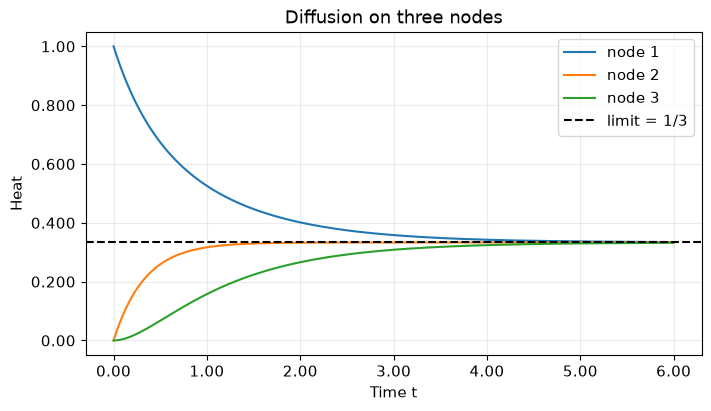

In [5]:
show_math(r'\begin{aligned}'
          r'\mathbf{u}(t)&=\sum_{k=0}^{2}e^{-\lambda_k t}'
          r'\mathbf{q}_k(\mathbf{q}_k^{\mathsf T}\mathbf{u}_0)\\'
          r'&=\frac{1}{3}\begin{pmatrix}1\\1\\1\end{pmatrix}'
          r'+\frac{e^{-t}}{2}\begin{pmatrix}1\\0\\-1\end{pmatrix}'
          r'+\frac{e^{-3t}}{6}\begin{pmatrix}1\\-2\\1\end{pmatrix}\\'
          r'&=\begin{pmatrix}\frac13+\frac12e^{-t}+\frac16e^{-3t}\\'
          r'\frac13-\frac13e^{-3t}\\'
          r'\frac13-\frac12e^{-t}+\frac16e^{-3t}\end{pmatrix}'
          r'\end{aligned}')

times = np.linspace(0, 6, 181)
heat = np.array([expm(-t * L) @ u0 for t in times])
analytical = np.column_stack([
    1 / 3 + np.exp(-times) / 2 + np.exp(-3 * times) / 6,
    1 / 3 - np.exp(-3 * times) / 3,
    1 / 3 - np.exp(-times) / 2 + np.exp(-3 * times) / 6,
])
np.testing.assert_allclose(heat, analytical, atol=1.00e-13)
pprint({'手計算とexpmの最大誤差': sig3(np.max(np.abs(heat - analytical)))})

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
for i in range(3):
    ax.plot(times, heat[:, i], label=f'node {i + 1}')
ax.axhline(1 / 3, color='black', linestyle='--', label='limit = 1/3')
ax.set(xlabel='Time t', ylabel='Heat', title='Diffusion on three nodes')
format_axes(ax)
ax.legend()
save_svg(fig, '02_path_diffusion.svg')

$t=1$ の熱量は順に $0.526,0.317,0.158$ となる。表示値の合計が厳密に1にならないのは丸めによる。私は、最初にこの小さな例で符号と初期値を確認する方が理解しやすいと感じる。

次の図はHeat Kernelそのものを示す。列が熱源、行が観測する頂点である。時刻が進むと、どの列も一様な分布へ近づく。

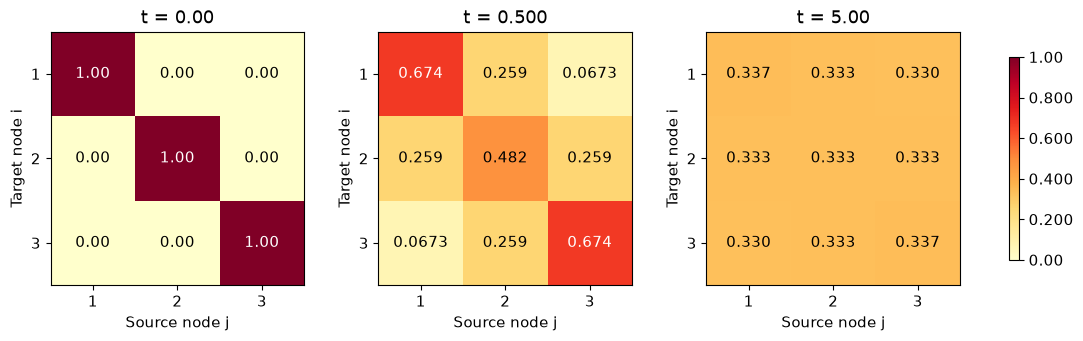

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.30), layout='constrained')
for ax, t in zip(axes, [0, 0.500, 5.00]):
    H = expm(-t * L)
    im = ax.imshow(H, cmap='YlOrRd', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            color = 'white' if H[i, j] > 0.600 else 'black'
            ax.text(j, i, sig3(H[i, j]), ha='center', va='center', color=color)
    ax.set(xticks=range(3), xticklabels=[1, 2, 3],
           yticks=range(3), yticklabels=[1, 2, 3],
           xlabel='Source node j', ylabel='Target node i', title=f't = {sig3(t)}')
cbar = fig.colorbar(im, ax=axes, shrink=0.800)
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: sig3(x)))
save_svg(fig, '03_heat_kernels.svg')

## 4. 保存される量と固有値の役割

全成分が1のベクトルを $\mathbf{1}$ とする。行和が0なので $\mathbf{L}\mathbf{1}=\mathbf{0}$ であり、対称性から熱量の総和が保存される。

$$
\frac{d}{dt}(\mathbf{1}^{\mathsf T}\mathbf{u})
=-\mathbf{1}^{\mathsf T}\mathbf{L}\mathbf{u}=0.
$$

また、$a=\max_i d_i>0$、$\mathbf{P}=\mathbf{I}-\mathbf{L}/a$ と置くと、$\mathbf{P}$ の各成分は非負である。

$$
\mathbf{H}_t=e^{at(\mathbf{P}-\mathbf{I})}
=e^{-at}\sum_{m=0}^{\infty}\frac{(at)^m}{m!}\mathbf{P}^m.
$$

したがって $t\geq0$ で $\mathbf{H}_t$ も非負であり、非負の初期値は非負のままである。総和が1なら、各辺の遷移率を $w_{ij}$ とする連続時間ランダムウォークの確率分布としても読める。

固有値が非負であることは、任意の実ベクトル $\mathbf{x}$ に対する次の計算で分かる。

$$
\begin{aligned}
\mathbf{x}^{\mathsf T}\mathbf{L}\mathbf{x}
&=\sum_i d_ix_i^2-\sum_{i,j}w_{ij}x_ix_j\\
&=\frac12\sum_{i,j}w_{ij}(x_i^2+x_j^2-2x_ix_j)\\
&=\frac12\sum_{i,j}w_{ij}(x_i-x_j)^2\geq0.
\end{aligned}
$$

連結なら等号は全成分が等しい場合に限る。固有値を $0=\lambda_0<\lambda_1\leq\cdots$ と並べ、正規直交固有ベクトルを $\mathbf{q}_k$ とすると、$\mathbf{q}_0=\mathbf{1}/\sqrt{n}$ だけが減衰せずに残る。

$$\mathbf{H}_t=\sum_{k=0}^{n-1}e^{-t\lambda_k}\mathbf{q}_k\mathbf{q}_k^{\mathsf T},\qquad\lim_{t\to\infty}\mathbf{H}_t=\frac{\mathbf{1}\mathbf{1}^{\mathsf T}}{n}$$

$$\mathbf{u}_{\infty}=\bar{u}\mathbf{1},\qquad\bar{u}=\frac{\mathbf{1}^{\mathsf T}\mathbf{u}_0}{n}$$

{'固有分解との最大誤差': '2.89e-15', '熱量の総和の最大誤差': '1.78e-15'}


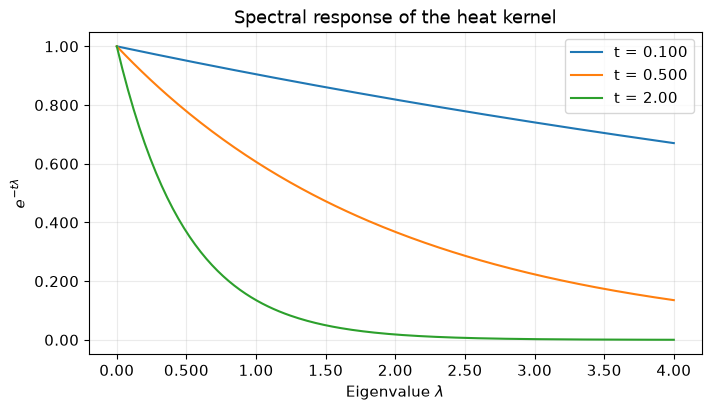

In [7]:
show_math(r'\mathbf{H}_t=\sum_{k=0}^{n-1}e^{-t\lambda_k}'
          r'\mathbf{q}_k\mathbf{q}_k^{\mathsf T},\qquad'
          r'\lim_{t\to\infty}\mathbf{H}_t='
          r'\frac{\mathbf{1}\mathbf{1}^{\mathsf T}}{n}')
show_math(r'\mathbf{u}_{\infty}=\bar{u}\mathbf{1},\qquad'
          r'\bar{u}=\frac{\mathbf{1}^{\mathsf T}\mathbf{u}_0}{n}')

# 固有分解による計算と行列指数関数を照合する。
eigenvalues, Q = eigh(L)
H_spectral = (Q * np.exp(-eigenvalues)) @ Q.T
np.testing.assert_allclose(H1, H_spectral, atol=1.00e-13)
np.testing.assert_allclose(H1.sum(axis=0), np.ones(3), atol=1.00e-13)
np.testing.assert_allclose(H1.sum(axis=1), np.ones(3), atol=1.00e-13)
assert H1.min() >= -1.00e-14
np.testing.assert_allclose(expm(-2 * L), H1 @ H1, atol=1.00e-13)
pprint({'熱量の総和の最大誤差': sig3(np.max(np.abs(heat.sum(axis=1) - 1))),
        '固有分解との最大誤差': sig3(np.max(np.abs(H1 - H_spectral)))})

# 大きな固有値に対応する成分ほど速く減衰する。
lam = np.linspace(0, 4, 200)
fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
for t in [0.100, 0.500, 2.00]:
    ax.plot(lam, np.exp(-t * lam), label=f't = {sig3(t)}')
ax.set(xlabel=r'Eigenvalue $\lambda$', ylabel=r'$e^{-t\lambda}$',
       title='Spectral response of the heat kernel')
format_axes(ax)
ax.legend()
save_svg(fig, '04_spectral_response.svg')

非連結なら、熱は連結成分を越えて移動せず、成分ごとの平均に収束する。また、一様な極限はここで選んだ組合せラプラシアンによる。各頂点から出る総遷移率を1にそろえる別の歩行では、定常分布は次数に比例する。

## 5. 細い接続と拡散の速さ

平均からの差の初期係数を $c_k=\mathbf{q}_k^{\mathsf T}\mathbf{u}_0$ とする。直交性を使うと、

$$
\begin{aligned}
\|\mathbf{u}(t)-\bar{u}\mathbf{1}\|_2^2
&=\sum_{k=1}^{n-1}e^{-2t\lambda_k}c_k^2\\
&\leq e^{-2t\lambda_1}\sum_{k=1}^{n-1}c_k^2\\
&=e^{-2t\lambda_1}\|\mathbf{u}_0-\bar{u}\mathbf{1}\|_2^2.
\end{aligned}
$$

平方根を取ると、距離は初期距離の $e^{-t\lambda_1}$ 倍以下になる。$\lambda_1$ はスペクトルギャップである。初期値がその固有ベクトル成分を含まなければ、さらに速く減衰する。

4頂点の完全グラフ2つを1本の辺で結ぶ。群内の重みは1、橋の重みは $w$ とし、左群の各頂点に $1/4$ ずつ熱を置く。まず $w=0.150$ の変化を見る。疎行列に対する `expm_multiply` は、密なHeat Kernel全体を作らずに、そのベクトルへの作用を計算する。

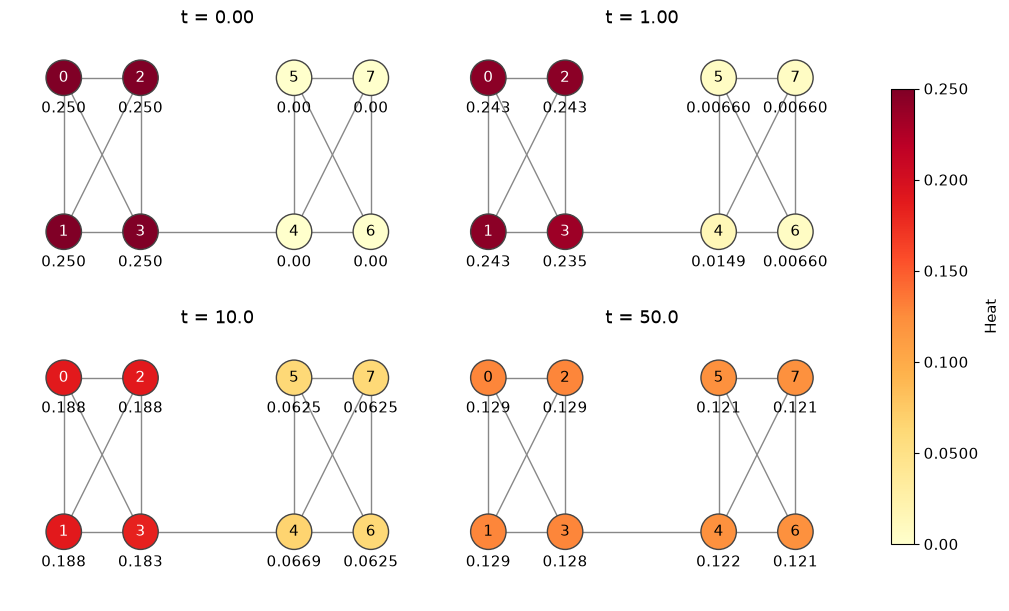

In [8]:
def bridge_graph(weight):
    """2つの完全グラフを、重み付きの橋で接続する。"""
    graph = nx.disjoint_union(nx.complete_graph(4), nx.complete_graph(4))
    nx.set_edge_attributes(graph, 1, 'weight')
    graph.add_edge(3, 4, weight=weight)
    return graph


bridge = bridge_graph(0.150)
L_bridge = nx.laplacian_matrix(bridge, nodelist=range(8)).astype(float)
initial = np.array([1, 1, 1, 1, 0, 0, 0, 0], dtype=float) / 4
steady = np.ones(8) / 8
positions = {0: (-2, 1), 1: (-2, -1), 2: (-1, 1), 3: (-1, -1),
             4: (1, -1), 5: (1, 1), 6: (2, -1), 7: (2, 1)}

fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout='constrained')
for ax, t in zip(axes.flat, [0, 1, 10, 50]):
    values = expm_multiply(-t * L_bridge, initial)
    nx.draw_networkx_edges(bridge, positions, ax=ax, edge_color='#888888')
    nodes = nx.draw_networkx_nodes(
        bridge, positions, ax=ax, node_color=values, cmap='YlOrRd',
        vmin=0, vmax=0.250, node_size=650, edgecolors='#444444',
    )
    # 色に加えて数値も書き、同じ尺度で時刻を比較する。
    for node, (x, y) in positions.items():
        ax.text(x, y, str(node), ha='center', va='center',
                color='white' if values[node] > 0.150 else 'black')
        ax.text(x, y - 0.450, sig3(values[node]), ha='center')
    ax.set_title(f't = {sig3(t)}')
    ax.set(xlim=(-2.70, 2.70), ylim=(-1.90, 1.60))
    ax.axis('off')
cbar = fig.colorbar(nodes, ax=list(axes.flat), shrink=0.800, label='Heat')
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: sig3(x)))
save_svg(fig, '05_bridge_diffusion.svg')

次に橋の重みだけを変える。実線は平均からの距離、破線は先ほどの上界である。この初期値では両者は近く、線はほぼ重なる。橋の重みを小さくするとギャップが小さくなり、左右の熱量の差が長く残る。

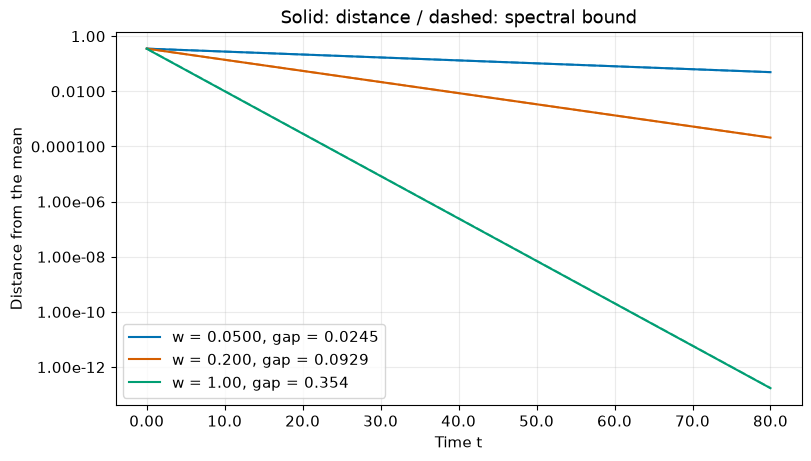

[{'橋の重み': '0.0500', 'ギャップ': '0.0245', '時刻80の距離': '0.0497'},
 {'橋の重み': '0.200', 'ギャップ': '0.0929', '時刻80の距離': '0.000210'},
 {'橋の重み': '1.00', 'ギャップ': '0.354', '時刻80の距離': '1.72e-13'}]
手計算との一致、保存則、非負性、半群性、減衰上界を確認した。
SVG保存先: 106_nb_files


In [9]:
grid = np.linspace(0, 80, 161)
initial_distance = np.linalg.norm(initial - steady)
fig, ax = plt.subplots(figsize=(8, 4.50), layout='constrained')
report = []
for weight, color in zip([0.0500, 0.200, 1.00], ['#0072B2', '#D55E00', '#009E73']):
    graph = bridge_graph(weight)
    sparse_L = nx.laplacian_matrix(graph, nodelist=range(8)).astype(float)
    gap = eigh(sparse_L.toarray(), eigvals_only=True)[1]
    # 等間隔の複数時刻をまとめて計算する。
    trajectory = expm_multiply(-sparse_L, initial, start=0, stop=80, num=len(grid))
    distance = np.linalg.norm(trajectory - steady, axis=1)
    bound = initial_distance * np.exp(-gap * grid)
    ax.semilogy(grid, distance, color=color,
                label=f'w = {sig3(weight)}, gap = {sig3(gap)}')
    ax.semilogy(grid, bound, '--', color=color, alpha=0.650)

    # 保存則・非負性・減衰上界と、別方式の計算を確認する。
    np.testing.assert_allclose(trajectory.sum(axis=1), np.ones(len(grid)), atol=1.00e-12)
    assert trajectory.min() >= -1.00e-12
    assert np.all(distance <= bound + 1.00e-12)
    np.testing.assert_allclose(
        trajectory[10], expm(-grid[10] * sparse_L.toarray()) @ initial, atol=1.00e-12,
    )
    report.append({'橋の重み': sig3(weight), 'ギャップ': sig3(gap),
                   '時刻80の距離': sig3(distance[-1])})

ax.set(xlabel='Time t', ylabel='Distance from the mean',
       title='Solid: distance / dashed: spectral bound')
format_axes(ax)
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.legend()
save_svg(fig, '06_bridge_mixing.svg')
pprint(report, sort_dicts=False)
print('手計算との一致、保存則、非負性、半群性、減衰上界を確認した。')
print(f'SVG保存先: {OUT}')

## 結論

この記事では、グラフ上の拡散をHeat Kernelで表し、手計算とPythonで熱量保存・平均への収束・固有値による減衰を確認した。

連結な無向グラフでは、組合せラプラシアンによる拡散は初期値の平均へ向かう。辺の弱い接続は小さいスペクトルギャップを生み、群をまたぐ拡散を遅くする。小規模な例では `expm`、疎なグラフで分布だけが必要なら `expm_multiply` が使える。

参考文献は、ラプラシアンの定義と実装に関する [NetworkX公式資料](https://networkx.org/documentation/stable/reference/generated/networkx.linalg.laplacianmatrix.laplacian_matrix.html)、行列指数関数の [SciPy expm](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.expm.html)、その作用を計算する [SciPy expm_multiply](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.expm_multiply.html) である。